# 2025 — GRPO: Reinforcement Learning with Verifiable Rewards

**Papers:** Zhihong Shao et al., *"DeepSeekMath"* (2024), which introduced **Group Relative Policy Optimization**; DeepSeek-AI, *"DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning"* (January 2025). Background: PPO (Schulman et al., 2017), RLHF (Ouyang et al., 2022).

The 2025 shift in LLM training: after pre-training, run RL on tasks whose answers can be **checked automatically** (math, code, puzzles), rewarding correct final answers. This RLVR produced "reasoning models" that think at length before answering.

**GRPO** drops PPO's value network. For each prompt $q$, sample a **group** of $G$ answers, score them, and use the group statistics as the baseline:

$$A_i = \frac{r_i - \operatorname{mean}(r_{1..G})}{\operatorname{std}(r_{1..G})}$$

$$\mathcal J = \mathbb E\Big[\frac1G\sum_i \frac1{|o_i|}\sum_t \min\big(\rho_{i,t}A_i,\ \operatorname{clip}(\rho_{i,t}, 1\pm\epsilon)A_i\big)\Big] - \beta\, \mathbb D_{KL}(\pi_\theta\|\pi_{\text{ref}}), \qquad \rho_{i,t} = \frac{\pi_\theta(o_{i,t}\mid q, o_{i,<t})}{\pi_{\text{old}}(o_{i,t}\mid q, o_{i,<t})}$$

**Toy task:** given a target number $S$, the policy must write 3 digits that **sum to $S$**. Correct answers are easy to verify and hard to guess (a random policy succeeds a few percent of the time). We pre-train nothing; GRPO alone drives the policy from random to near-perfect.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
import copy

PyTorch 2.15.0 | device: mps


In [2]:
N_DIG, S_MIN, S_MAX = 3, 3, 24
V = 10 + (S_MAX + 1)                       # tokens 0-9 = digits, 10+S = "target S" prompt token

class Policy(nn.Module):
    """A tiny autoregressive model: prompt token, then N_DIG digit tokens."""
    def __init__(self, d=128):
        super().__init__()
        self.emb = nn.Embedding(V, d); self.rnn = nn.GRU(d, d, batch_first=True); self.head = nn.Linear(d, 10)
    def forward(self, seq):                # seq: (B, T) -> logits over digits for the next position
        return self.head(self.rnn(self.emb(seq))[0])

@torch.no_grad()
def sample(policy, targets, G):
    """For each prompt draw G completions. Returns sequences (B*G, 1+N_DIG)."""
    seq = (10 + targets).repeat_interleave(G)[:, None]
    for _ in range(N_DIG):
        nxt = torch.multinomial(policy(seq)[:, -1].softmax(-1), 1)
        seq = torch.cat([seq, nxt], 1)
    return seq

def logprobs(policy, seq):
    logp = policy(seq[:, :-1]).log_softmax(-1)
    return logp.gather(-1, seq[:, 1:, None]).squeeze(-1)                     # (B*G, N_DIG) per-token log-probs

def reward(seq):
    """The verifier: 1 if the digits sum to the target, else 0."""
    target = seq[:, 0] - 10
    return (seq[:, 1:].sum(1) == target).float()

In [3]:
policy = Policy().to(device)
ref = copy.deepcopy(policy).eval()                                            # reference policy for the KL term
opt = torch.optim.Adam(policy.parameters(), lr=1e-3)
B, G, eps, beta, inner_steps = 32, 16, 0.2, 0.02, 2

def evaluate(policy, n=2000):
    t = torch.randint(S_MIN, S_MAX + 1, (n,), device=device)
    return reward(sample(policy, t, 1)).mean().item()

hist = []
for it in range(301):
    targets = torch.randint(S_MIN, S_MAX + 1, (B,), device=device)
    seq = sample(policy, targets, G)                                           # rollouts from pi_old
    r = reward(seq).view(B, G)
    adv = ((r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + 1e-4)).view(-1, 1)   # group-relative advantage
    with torch.no_grad():
        old_lp, ref_lp = logprobs(policy, seq), logprobs(ref, seq)
    for _ in range(inner_steps):                                               # a few updates per batch, PPO-style
        lp = logprobs(policy, seq)
        ratio = (lp - old_lp).exp()
        pg = torch.min(ratio * adv, ratio.clamp(1 - eps, 1 + eps) * adv)
        kl = (ref_lp - lp).exp() - (ref_lp - lp) - 1                            # k3 estimator used by GRPO
        loss = -(pg - beta * kl).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    hist.append((it, r.mean().item()))
    if it % 50 == 0: print(f"iter {it:3d}  mean reward of rollouts {r.mean():.3f}  | sampled eval accuracy {evaluate(policy):.3f}")

iter   0  mean reward of rollouts 0.059  | sampled eval accuracy 0.044


iter  50  mean reward of rollouts 0.365  | sampled eval accuracy 0.384


iter 100  mean reward of rollouts 0.896  | sampled eval accuracy 0.900


iter 150  mean reward of rollouts 0.930  | sampled eval accuracy 0.893


iter 200  mean reward of rollouts 0.926  | sampled eval accuracy 0.880


iter 250  mean reward of rollouts 0.953  | sampled eval accuracy 0.891


iter 300  mean reward of rollouts 0.947  | sampled eval accuracy 0.888


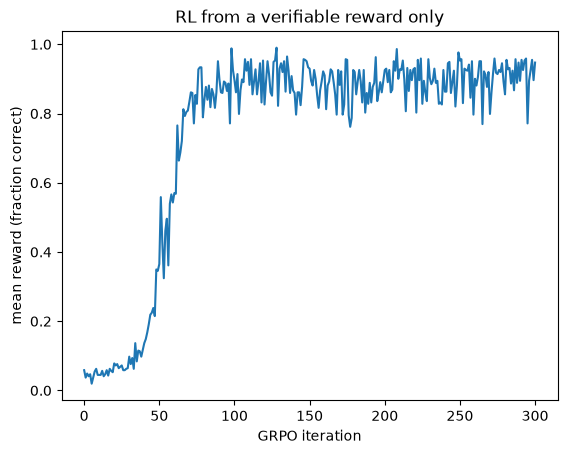

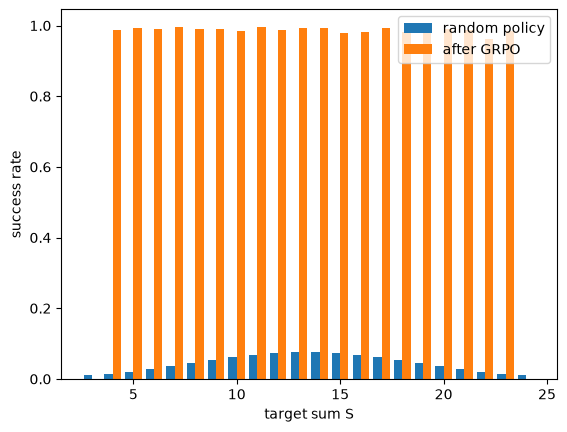

target  3: random policy 0.010 -> after GRPO 0.000
target  4: random policy 0.015 -> after GRPO 0.988
target  5: random policy 0.021 -> after GRPO 0.994
target 13: random policy 0.075 -> after GRPO 0.992
target 22: random policy 0.021 -> after GRPO 0.962
target 23: random policy 0.015 -> after GRPO 0.984
target 24: random policy 0.010 -> after GRPO 0.000
target  3: samples [[7, 9, 1], [9, 4, 1], [7, 8, 5], [9, 2, 5], [9, 2, 6]]
target 13: samples [[9, 2, 2], [2, 9, 2], [9, 2, 2], [9, 2, 2], [2, 2, 9]]
target 24: samples [[7, 3, 2], [9, 0, 7], [7, 2, 8], [8, 7, 4], [6, 9, 1]]


In [4]:
its, rs = zip(*hist)
plt.plot(its, rs); plt.xlabel("GRPO iteration"); plt.ylabel("mean reward (fraction correct)")
plt.title("RL from a verifiable reward only"); plt.show()

per_target = []
with torch.no_grad():
    for S in range(S_MIN, S_MAX + 1):
        per_target.append(reward(sample(policy, torch.full((500,), S, device=device), 1)).mean().item())
    rand = [sum(1 for a in range(10) for b in range(10) for c in range(10) if a + b + c == S) / 1000 for S in range(S_MIN, S_MAX + 1)]
plt.bar(np.arange(S_MIN, S_MAX + 1) - 0.2, rand, 0.4, label="random policy")
plt.bar(np.arange(S_MIN, S_MAX + 1) + 0.2, per_target, 0.4, label="after GRPO")
plt.xlabel("target sum S"); plt.ylabel("success rate"); plt.legend(); plt.show()
for S, a, r0 in zip(range(S_MIN, S_MAX + 1), per_target, rand):
    if S in (3, 4, 5, 13, 22, 23, 24): print(f"target {S:2d}: random policy {r0:.3f} -> after GRPO {a:.3f}")
for S in [3, 13, 24]:
    s = sample(policy, torch.tensor([S], device=device), 5)
    print(f"target {S:2d}: samples {[x[1:].tolist() for x in s]}")

## Why the group baseline works, and where it fails
If all $G$ answers to a prompt get the same reward, every advantage is 0 and that prompt teaches nothing. Learning comes from prompts where *some* answers succeed, and the good ones are pushed up relative to their siblings.

You can see the failure mode above. Targets near the extremes (3 or 24 have only 10 valid answers out of 1000) are rarely or never solved by the initial random policy, so they get almost no signal. Meanwhile the policy sharpens on the easy targets, which makes exploring the rare ones even less likely. That is why RLVR is applied **after** pre-training and SFT in real LLMs: the base model must already succeed sometimes. Practical fixes include curriculum/difficulty filtering, larger groups, and partial-credit rewards. Recent variants (DAPO, Dr. GRPO, GSPO, 2025) also adjust the normalisation, clipping and sequence-level ratios.